# 01 · E0: COCO-pretrained YOLOv8s, no KITTI training (baseline, RQ1)

**Question (RQ1).** How much does training on KITTI improve detection over a detector pretrained only on
general-purpose data?

This notebook gives the *before* number: YOLOv8s with its COCO weights (Ultralytics' release, trained on COCO's
118 000 everyday photos), used **as-is**. Nothing is trained. COCO's classes are mapped to KITTI's
(car → Car, truck → Truck, person → Pedestrian, bicycle → Cyclist, train → Tram); KITTI's Van, Misc and Person_sitting
have no COCO counterpart, so the baseline cannot find them. Notebooks 02 and 05 train the same architecture on KITTI.

**Setup.** Installs the pinned library versions on Kaggle and imports the shared code (`kitti_common.py`, written and
explained in `00_common.ipynb`): data access, the KITTI evaluator, training loops and plots.

In [1]:
SMOKE = False   # True = quick pipeline test (5 % of the data, 2 epochs); the numbers are then meaningless

import os, sys, json, subprocess
from pathlib import Path
os.environ["KITTI_SMOKE"] = "1" if SMOKE else "0"
if Path("/kaggle/input").exists():                     # Kaggle: install the pinned libraries, find the shared code
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.214", "albumentations==2.0.8"],
                   check=True)
    for r, dirs, files in os.walk("/kaggle/input"):
        if "kitti_common.py" in files:
            sys.path.insert(0, r)
            break
        dirs[:] = [d for d in dirs if not d.startswith(("images", "labels", "label_2"))]
from kitti_common import *
seed_everything()
print("Kaggle" if ON_KAGGLE else "local", "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
      "| smoke test" if SMOKE else "")

Kaggle | GPU: Tesla T4 


## Data

Only validation and test are needed (no training).

In [2]:
tables = prepare_data(["val", "test"])

copy images/val:   0%|          | 0/1239 [00:00<?, ?it/s]

copy labels/val:   0%|          | 0/1239 [00:00<?, ?it/s]

copy images/test:   0%|          | 0/1543 [00:00<?, ?it/s]

copy labels/test:   0%|          | 0/1543 [00:00<?, ?it/s]

data ready in /tmp/kitti: val 1239, test 1543


## Validation

In [3]:
info = {"model": "yolov8s.pt (COCO)", "imgsz": 640, "epochs_run": 0, "train_hours": 0.0,
        "settings": json.dumps({"class_map": {int(k): v for k, v in COCO_TO_KITTI.items()}})}
val, val_table, _ = evaluate_model("E0", "yolo", "yolov8s.pt", tables, "val", imgsz=640, class_map=COCO_TO_KITTI)
headline(validation=val)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


E0 on val:   0%|          | 0/78 [00:00<?, ?it/s]

,validation
"Primary (Car/Ped/Cyc, Moderate)",0.473
Car,0.888
Pedestrian,0.530
Cyclist,0.000
Easy (3 classes),0.507
Hard (3 classes),0.403
Car AP@0.7,0.663
"mAP@0.5, all 8 classes",0.223
"mAP@0.5:0.95, all 8 classes",0.111


## Test set (once)

Nothing about this model was chosen, so it is scored on the test set right away.

In [4]:
test, test_table, test_preds = evaluate_model("E0", "yolo", "yolov8s.pt", tables, "test", imgsz=640, class_map=COCO_TO_KITTI)
headline(validation=val, test=test)

E0 on test:   0%|          | 0/97 [00:00<?, ?it/s]

,validation,test
"Primary (Car/Ped/Cyc, Moderate)",0.473,0.542
Car,0.888,0.930
Pedestrian,0.530,0.687
Cyclist,0.000,0.008
Easy (3 classes),0.507,0.564
Hard (3 classes),0.403,0.503
Car AP@0.7,0.663,0.720
"mAP@0.5, all 8 classes",0.223,0.264
"mAP@0.5:0.95, all 8 classes",0.111,0.158


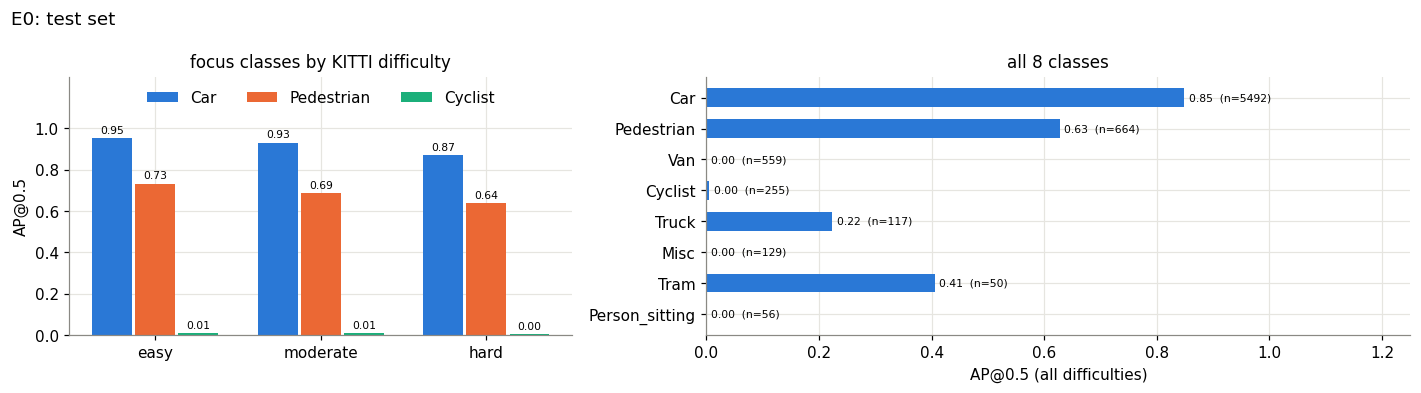

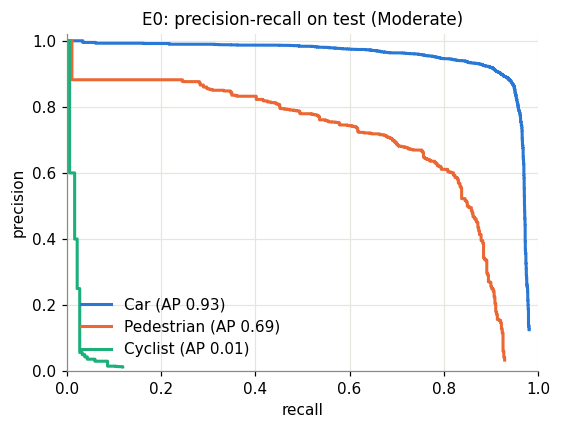

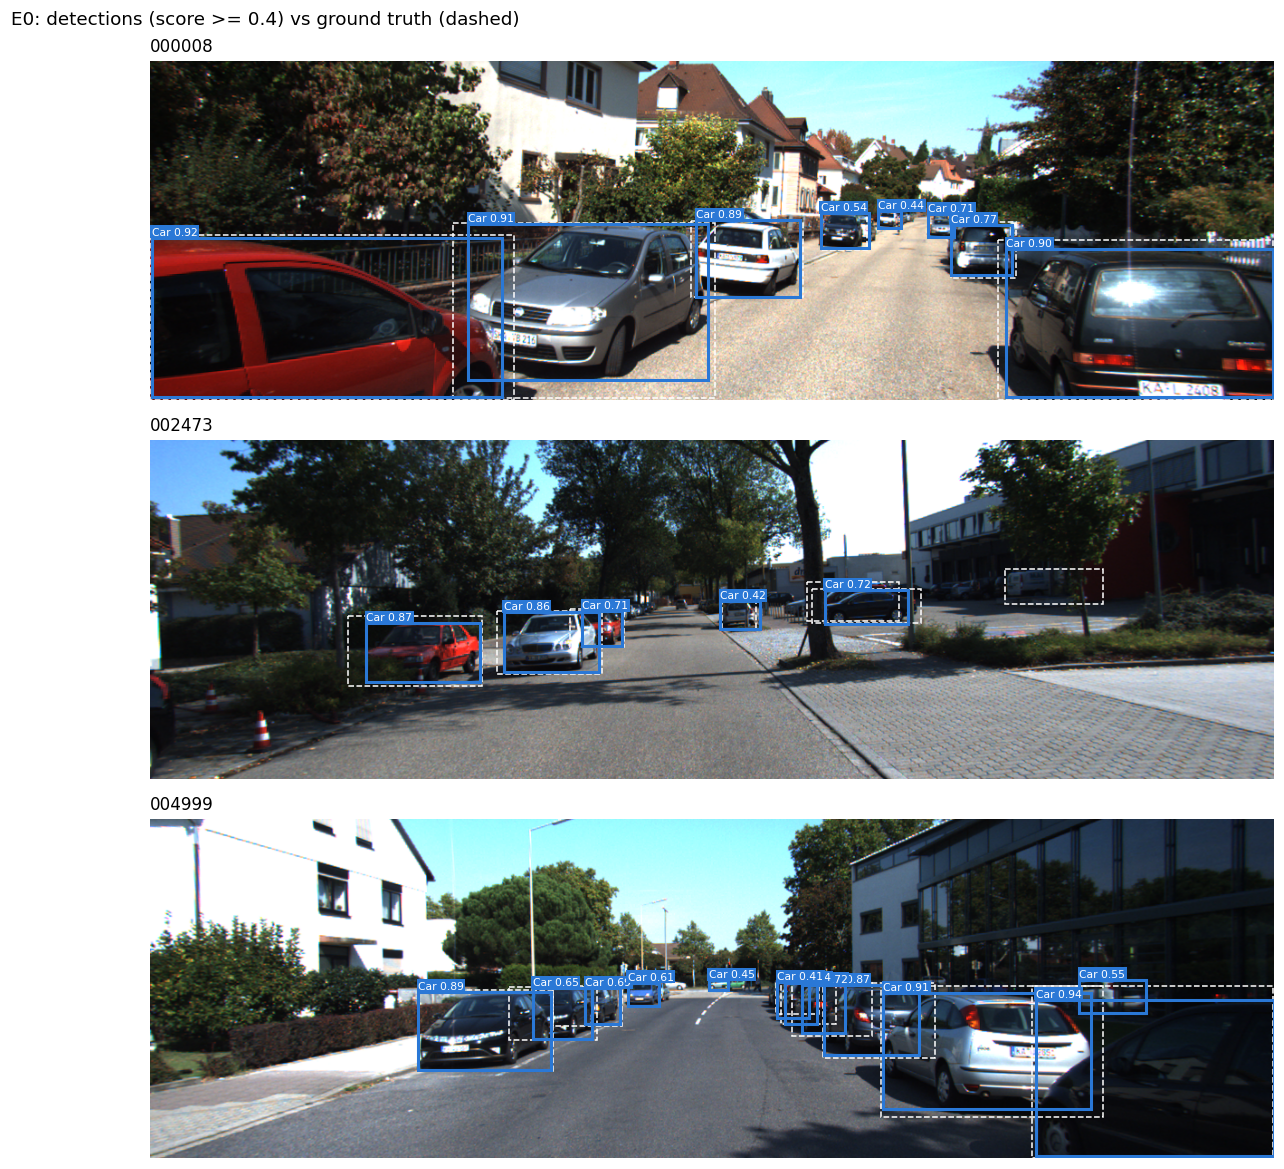

In [5]:
plot_per_class("E0", test_table, "test set")
plot_pr("E0", test_preds, tables, "test")
EXAMPLES = split_ids(tables[0], "test")[::max(1, len(split_ids(tables[0], "test")) // 3)][:3]
show_detections("E0", test_preds, tables, EXAMPLES)

## Observations

- **Primary metric: 0.473 on validation, 0.542 on test.** The COCO-only model is already strong on **cars**
  (test AP 0.930) and reasonable on **pedestrians** (0.687), because both are common COCO classes.
- **Cyclists are almost never detected (test AP 0.008).** COCO has no "cyclist" class: it sees a *person* and a
  *bicycle* as two separate objects. COCO's bicycle is mapped to Cyclist, but a box around the bicycle alone rarely
  overlaps a KITTI cyclist box (rider and bicycle together) enough to count, and the rider becomes a Pedestrian. This one class costs about 0.25 of the primary metric on its own.
- This is the lower bound for RQ1: everything later notebooks gain over 0.542 comes from training on KITTI.
- Test is higher than validation here and in every other notebook. The test drives are simply somewhat easier than the
  validation drives; that is why models are only ever compared on the **same** split.

## Record

In [6]:
rec = save_record("E0", "COCO-pretrained YOLOv8s, no KITTI training", "RQ1", val=val, test=test, **info)
pd.Series(rec).to_frame("value")

,value
exp_id,E0
description,"COCO-pretrained YOLOv8s, no KITTI training"
research_question,RQ1
model,yolov8s.pt (COCO)
imgsz,640
epochs_run,0
train_hours,0.0
settings,"{""class_map"": {""2"": ""Car"", ""7"": ""Truck"", ""0"": ..."
val_AP50_Car_easy,0.904662
val_AP50_Car_moderate,0.887788
